In [1]:
from pathlib import Path
import ctypes
import json
import numpy as np

# TensorFlow 2.21.0 omits cuSOLVER from its library search path. Preload it
# before importing TensorFlow so the CUDA libraries installed in this venv load.
try:
    import nvidia
    cusolver_lib = Path(next(iter(nvidia.__path__))) / 'cusolver' / 'lib' / 'libcusolver.so.11'
    if cusolver_lib.is_file():
        ctypes.CDLL(str(cusolver_lib), mode=ctypes.RTLD_GLOBAL)
except (ImportError, OSError, StopIteration) as error:
    print(f'cuSOLVER preload skipped: {error}')

import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
print(np.__version__)
print('TensorFlow:', tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print('GPUs:', gpus)
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)
SEED = 42
tf.keras.utils.set_random_seed(SEED)
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

I0000 00:00:1794034853.003665    9625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1794034853.943103    9625 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794034898.884307    9625 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


2.5.4
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
import os
import sys
import zipfile

PROJECT_DIR = Path.cwd().resolve()
if not (PROJECT_DIR / 'dataset').is_dir() and (PROJECT_DIR.parent / 'dataset').is_dir():
    PROJECT_DIR = PROJECT_DIR.parent
LOCAL_DATA_DIR = PROJECT_DIR / 'dataset'
ARCHIVE_PATH = PROJECT_DIR / 'data' / 'plant_disease_dataset.zip'
EXTRACT_DIR = PROJECT_DIR / 'data' / 'extracted'
DRIVE_FILE_ID = '1ZPNue82UJ6ySev2IBQnlvqRSbZrITkob'
DOWNLOAD_FROM_DRIVE_IF_MISSING = False


def find_dataset_root(base):
    base = Path(base)
    if {'train', 'val', 'test'}.issubset({p.name for p in base.iterdir() if p.is_dir()}) if base.is_dir() else False:
        return base
    if base.is_dir():
        for current, dirs, _ in os.walk(base):
            if {'train', 'val', 'test'}.issubset(dirs):
                return Path(current)
    return None

DATA_DIR = find_dataset_root(LOCAL_DATA_DIR)
if DATA_DIR is None and DOWNLOAD_FROM_DRIVE_IF_MISSING:
    try:
        import gdown
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', 'gdown'])
        import gdown
    ARCHIVE_PATH.parent.mkdir(parents=True, exist_ok=True)
    if not ARCHIVE_PATH.exists():
        downloaded = gdown.download(id=DRIVE_FILE_ID, output=str(ARCHIVE_PATH), quiet=False)
        if not downloaded or not ARCHIVE_PATH.exists() or ARCHIVE_PATH.stat().st_size < 1_000_000:
            raise RuntimeError('Dataset download failed. Check the Google Drive sharing settings.')
    EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE_PATH) as archive:
        bad_member = next((name for name in archive.namelist() if Path(name).is_absolute() or '..' in Path(name).parts), None)
        if bad_member:
            raise ValueError(f'Unsafe path in dataset archive: {bad_member}')
        archive.extractall(EXTRACT_DIR)
    DATA_DIR = find_dataset_root(EXTRACT_DIR)

if DATA_DIR is None:
    raise FileNotFoundError(
        f'Could not find train/val/test folders under {LOCAL_DATA_DIR}. '
        'Place the dataset there, or set DOWNLOAD_FROM_DRIVE_IF_MISSING = True.'
    )
print('Dataset folders found at:', DATA_DIR)

splits = ('train', 'val', 'test')
class_sets = {}
for split in splits:
    split_dir = DATA_DIR / split
    if not split_dir.is_dir():
        raise FileNotFoundError(f'Missing split folder: {split_dir.resolve()}')
    class_sets[split] = {p.name for p in split_dir.iterdir() if p.is_dir()}
    print(f'{split}: {len(class_sets[split])} classes')
if not class_sets['train']:
    raise ValueError('No class folders found inside dataset/train')
for split in ('val', 'test'):
    if class_sets[split] != class_sets['train']:
        raise ValueError(f'{split} class folders do not match train. Missing: {sorted(class_sets["train"] - class_sets[split])}; extra: {sorted(class_sets[split] - class_sets["train"])}')
CLASS_NAMES = sorted(class_sets['train'])
print(f'Classes ({len(CLASS_NAMES)}):', CLASS_NAMES)

Dataset folders found at: /mnt/c/Vivek/clg/code/Plant_Disease_Detector-/dataset
train: 46 classes
val: 46 classes
test: 46 classes
Classes (46): ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Brown spot', 'Apple___Cedar_apple_rust', 'Apple___Grey spot', 'Apple___Mosaic', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___Powdery_mildew', 'Cherry___healthy', 'Corn___Cercospora_leaf_spot_Gray_leaf_spot', 'Corn___Common_rust', 'Corn___Northern_Leaf_Blight', 'Corn___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Rice___Brown_Spot', 'Rice___Healthy', 'Rice___Leaf_Blast', 'Rice___Neck_Blast', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', '

In [3]:
import random

MAX_TRAIN_PER_CLASS = 200
MAX_VAL_PER_CLASS = 100
IMAGE_EXTENSIONS = {'.jpg', '.jpeg', '.png', '.bmp'}
AUTOTUNE = tf.data.AUTOTUNE

def load_split(split, shuffle):
    paths, labels = [], []
    for class_id, class_name in enumerate(CLASS_NAMES):
        files = sorted(p for p in (DATA_DIR / split / class_name).iterdir() if p.suffix.lower() in IMAGE_EXTENSIONS)
        limit = MAX_TRAIN_PER_CLASS if split == 'train' else (MAX_VAL_PER_CLASS if split == 'val' else 0)
        if limit and len(files) > limit:
            files = random.Random(SEED + class_id + (100000 if split == 'val' else 0)).sample(files, limit)
        paths.extend(str(p) for p in files)
        labels.extend([class_id] * len(files))
    if not paths:
        raise ValueError(f'No supported images found in {DATA_DIR / split}')
    print(f'{split}: {len(paths):,} images')
    ds = tf.data.Dataset.from_tensor_slices((paths, np.asarray(labels, dtype=np.int32)))
    if shuffle:
        ds = ds.shuffle(min(len(paths), 10000), seed=SEED, reshuffle_each_iteration=True)
    def decode_image(path, label):
        image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
        image.set_shape([None, None, 3])
        image = tf.image.resize(image, IMG_SIZE)
        return image, label
    return ds.map(decode_image, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = load_split('train', True)
val_ds = load_split('val', False)
test_ds = load_split('test', False)

train: 9,200 images


I0000 00:00:1794034944.199824    9625 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


val: 4,600 images
test: 19,218 images


In [4]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip('horizontal'),
    tf.keras.layers.RandomRotation(0.08),
    tf.keras.layers.RandomZoom(0.1),
], name='data_augmentation')

base_model = tf.keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights='imagenet'
)
base_model.trainable = False

inputs = tf.keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = tf.keras.applications.mobilenet_v2.preprocess_input(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.25)(x)
outputs = tf.keras.layers.Dense(len(CLASS_NAMES), activation='softmax')(x)
model = tf.keras.Model(inputs, outputs)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 46)             │        58,926 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,316,910 (8.84 MB)

 Trainable params: 58,926 (230.18 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [5]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', patience=2, factor=0.3),
]
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
history_head = model.fit(train_ds, validation_data=val_ds, epochs=5, callbacks=callbacks)

Epoch 1/5


/mnt/c/Vivek/clg/code/Plant_Disease_Detector-/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
I0000 00:00:1794034954.629628   10006 cuda_dnn.cc:461] Loaded cuDNN version 92700


288/288 ━━━━━━━━━━━━━━━━━━━━ 37s 83ms/step - accuracy: 0.6268 - loss: 1.3920 - val_accuracy: 0.7991 - val_loss: 0.6955 - learning_rate: 0.0010
Epoch 2/5
288/288 ━━━━━━━━━━━━━━━━━━━━ 19s 66ms/step - accuracy: 0.8255 - loss: 0.5637 - val_accuracy: 0.8393 - val_loss: 0.5248 - learning_rate: 0.0010
Epoch 3/5
288/288 ━━━━━━━━━━━━━━━━━━━━ 22s 76ms/step - accuracy: 0.8722 - loss: 0.4259 - val_accuracy: 0.8376 - val_loss: 0.5086 - learning_rate: 0.0010
Epoch 4/5
288/288 ━━━━━━━━━━━━━━━━━━━━ 19s 65ms/step - accuracy: 0.8837 - loss: 0.3638 - val_accuracy: 0.8513 - val_loss: 0.4596 - learning_rate: 0.0010
Epoch 5/5
288/288 ━━━━━━━━━━━━━━━━━━━━ 23s 80ms/step - accuracy: 0.8974 - loss: 0.3212 - val_accuracy: 0.8728 - val_loss: 0.3921 - learning_rate: 0.0010


In [6]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
# Keep BatchNormalization statistics fixed while fine-tuning.
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
history_fine = model.fit(train_ds, validation_data=val_ds, epochs=3, callbacks=callbacks)

Epoch 1/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 33s 91ms/step - accuracy: 0.9132 - loss: 0.2518 - val_accuracy: 0.8676 - val_loss: 0.3935 - learning_rate: 1.0000e-05
Epoch 2/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 26s 89ms/step - accuracy: 0.9220 - loss: 0.2152 - val_accuracy: 0.8852 - val_loss: 0.3552 - learning_rate: 1.0000e-05
Epoch 3/3
288/288 ━━━━━━━━━━━━━━━━━━━━ 23s 78ms/step - accuracy: 0.9305 - loss: 0.1947 - val_accuracy: 0.8863 - val_loss: 0.3562 - learning_rate: 1.0000e-05


In [7]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
probabilities = model.predict(test_ds, verbose=1)
y_pred = np.argmax(probabilities, axis=1)
y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
print(f'Test accuracy: {test_accuracy:.4f}')
print(classification_report(y_true, y_pred, labels=range(len(CLASS_NAMES)), target_names=CLASS_NAMES, zero_division=0, digits=3))

601/601 ━━━━━━━━━━━━━━━━━━━━ 30s 49ms/step - accuracy: 0.8902 - loss: 0.3443
601/601 ━━━━━━━━━━━━━━━━━━━━ 30s 49ms/step
Test accuracy: 0.8902
                                               precision    recall  f1-score   support

                           Apple___Apple_scab      0.937     0.883     0.909       504
                            Apple___Black_rot      0.985     0.924     0.953       497
                           Apple___Brown spot      0.987     0.964     0.976       394
                     Apple___Cedar_apple_rust      0.961     0.834     0.893       440
                            Apple___Grey spot      0.819     0.989     0.896       187
                               Apple___Mosaic      0.904     0.976     0.939       251
                              Apple___healthy      0.899     0.976     0.936       502
                          Blueberry___healthy      0.983     0.919     0.950       454
                      Cherry___Powdery_mildew      0.971     0.969     0.9

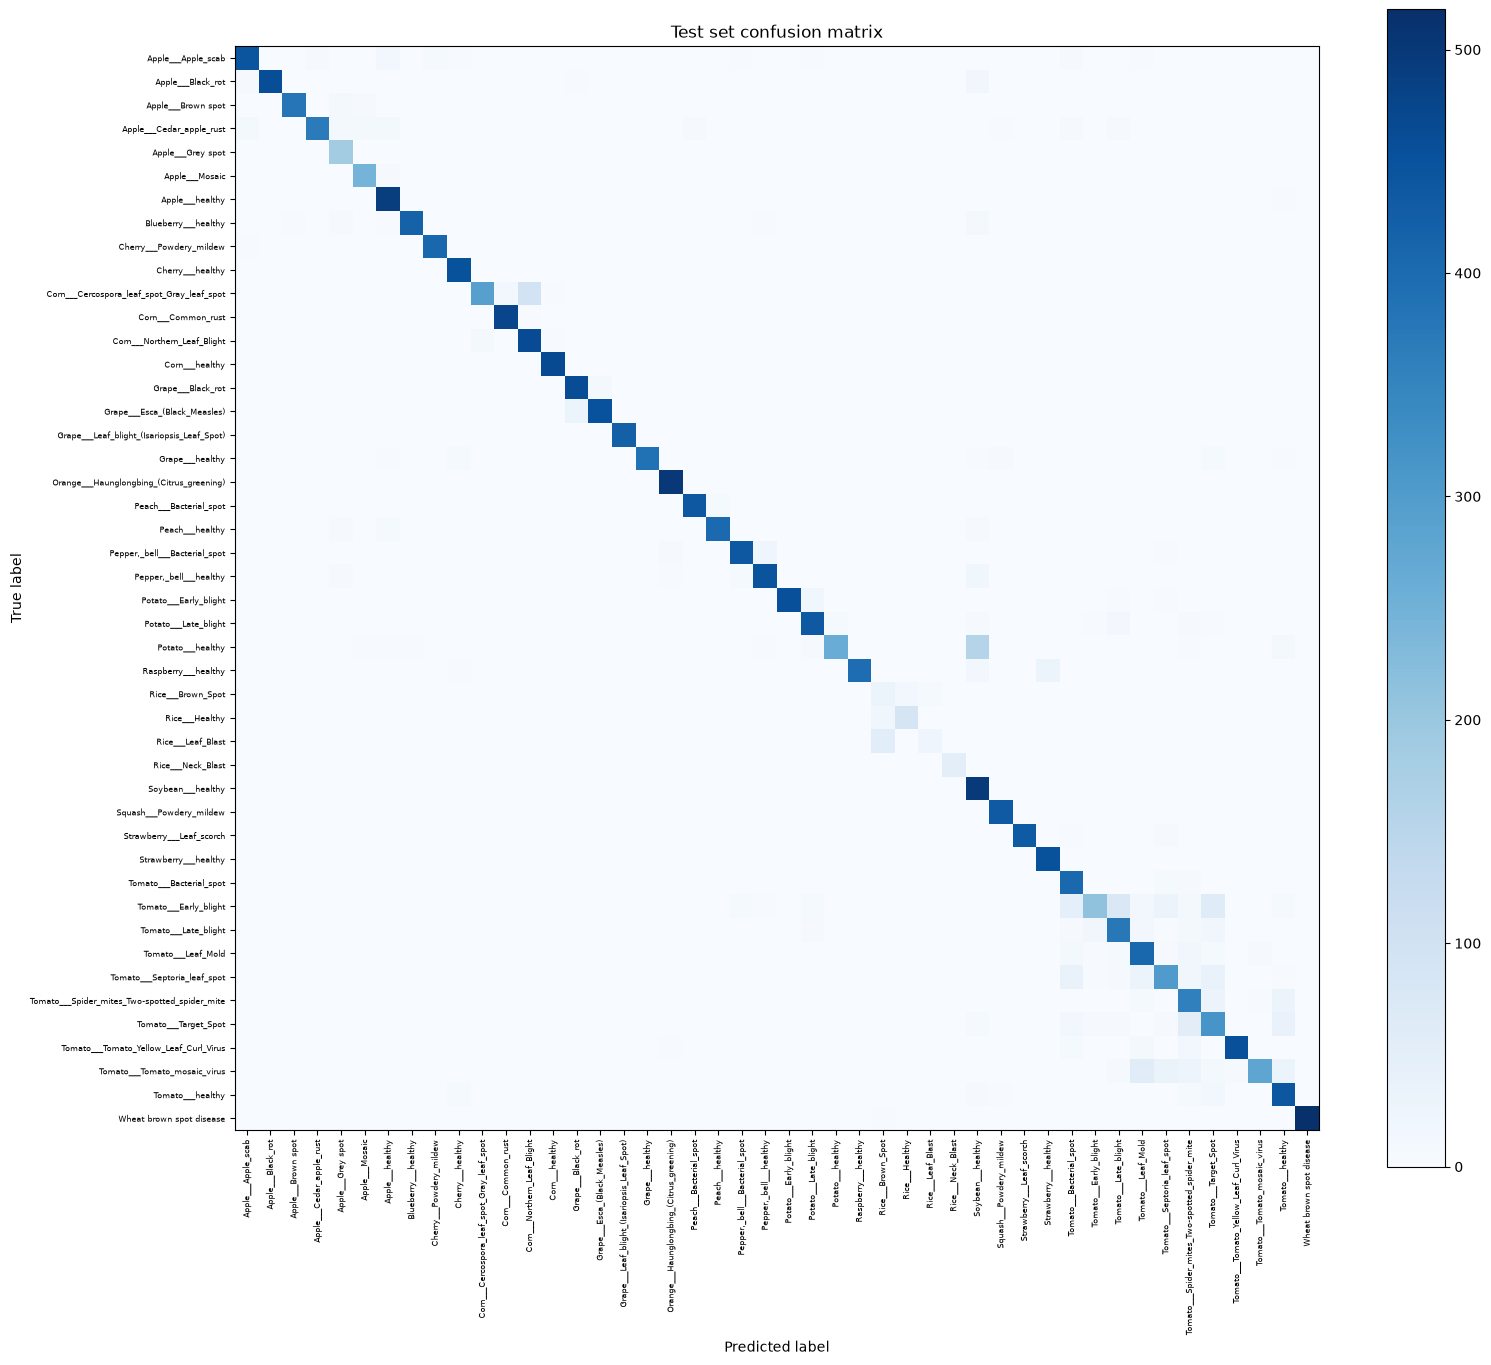

In [8]:
cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASS_NAMES)))
fig, ax = plt.subplots(figsize=(max(10, len(CLASS_NAMES) * 0.35), max(8, len(CLASS_NAMES) * 0.3)))
image = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES, rotation=90, fontsize=6)
ax.set_yticks(range(len(CLASS_NAMES)), CLASS_NAMES, fontsize=6)
ax.set_xlabel('Predicted label')
ax.set_ylabel('True label')
ax.set_title('Test set confusion matrix')
fig.colorbar(image, ax=ax)
fig.tight_layout()
plt.show()

In [9]:
OUTPUT_DIR = PROJECT_DIR / 'model_comparison' / 'results' / 'mobilenetv2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
model.save(OUTPUT_DIR / 'model.keras')
(OUTPUT_DIR / 'class_names.json').write_text(json.dumps(CLASS_NAMES, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps({
    'test_loss': float(test_loss),
    'test_accuracy': float(test_accuracy),
    'num_classes': len(CLASS_NAMES),
}, indent=2), encoding='utf-8')
print(f'Saved model and metadata to {OUTPUT_DIR}')

Saved model and metadata to /mnt/c/Vivek/clg/code/Plant_Disease_Detector-/model_comparison/results/mobilenetv2
